#Анализ реакций на странице Чэнь Ду Линь


Для анализа взяла персональную страницу китайской актрисы Чэнь Ду Линь на [вейбо](https://www.weibo.com/u/5589792153).
С помощью [weibo-crawler](https://github.com/dataabc/weibo-crawler) собрала датасет из постов за год (365 дней) в файл [weibo_posts.csv](https://docs.google.com/spreadsheets/d/186A2fPHnAxRpjmj_JZzCLqxJuQOXwG5HKbuumVtyiYU/edit?usp=sharing).

In [ ]:
import pandas as pd
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import re
from google.colab import drive
drive.mount('/content/gdrive')

PATH_TO_DATA = '/content/gdrive/My Drive/Weibo/'

df = pd.read_csv(PATH_TO_DATA + 'weibo_posts.csv')
df.columns = ['id', 'bid', 'text', 'head_url', 'original_pic_url', 'video_url', 'live_photo_url', 'location', 'created_at', 'tool', 'likes_count', 'comments_count', 'reposts_count', 'topics', 'user', 'full_date', 'edited', 'edits_count']


Mounted at /content/gdrive


###Временной анализ
Посмотрим, влияет ли момент публикации (час, день недели, интервал между постами) на лайки, комментарии и репосты. Сначала подготавливаем признаки для анализа.  

In [ ]:
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")

# Час дня и день недели
df["hour"] = df["created_at"].dt.hour
df["day_of_week"] = df["created_at"].dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["day_of_week"] = pd.Categorical(df["day_of_week"], categories=day_order, ordered=True)

# Промежуток между постами (в часах)
df = df.sort_values("created_at").reset_index(drop=True)
df["hours_since_prev"] = df["created_at"].diff().dt.total_seconds() / 3600
df["hours_since_prev"] = df["hours_since_prev"].fillna(df["hours_since_prev"].median())

Смотрим на медианное количество лайков, комментов и репостов по часам.

In [ ]:
df.groupby("hour")[["likes_count", "comments_count", "reposts_count"]].median()

,likes_count,comments_count,reposts_count
hour,,,
0,428709.0,256954.5,536272.0
1,154504.0,121191.0,157854.0
9,162973.0,109170.0,60144.0
10,104654.0,64246.5,78024.5
11,78430.0,31580.0,44328.0
12,116695.0,67548.0,78570.0
13,130434.0,60880.0,72333.0
14,146721.0,47554.0,64007.0
15,92620.0,17167.0,34888.0


С двух ночи до 8 утра постов нет. В полночь аномальные значения по количеству реакций - выводим посты для отдельного анализа.  

In [ ]:
df[df["hour"] == 0]

,id,bid,text,head_url,original_pic_url,video_url,live_photo_url,location,created_at,tool,...,reposts_count,topics,user,full_date,edited,edits_count,hour,time_of_day,day_of_week,hours_since_prev
4,5222887185188867,Q9BoOlLRp,NaN,NaN,NaN,NaN,NaN,NaN,2025-10-18 00:00:04,生日动态,...,1000000,NaN,NaN,2025-10-18 00:00:04,False,0,0,Night,Saturday,8.908333
26,5246449967432239,QjunivbsP,NaN,NaN,NaN,NaN,NaN,NaN,2025-12-22 00:30:09,明星动态,...,72544,NaN,NaN,2025-12-22 00:30:09,False,0,0,Night,Monday,8.625556


Аномалию создал пост в день рождения актрисы - 18 октября. (из-за особенностей платформы максимум репостов отображается как миллион). Второй полночный пост относится к премии Tencent Weibo Night. Всплеск активности аудитории объясним, но для выявления закономерностей не учитывается.  

Для наглядности рисуем график, показывающий суточный ритм каждой метрики отдельно. Медианы логарифмируем для сглаживания больших диапазонов.

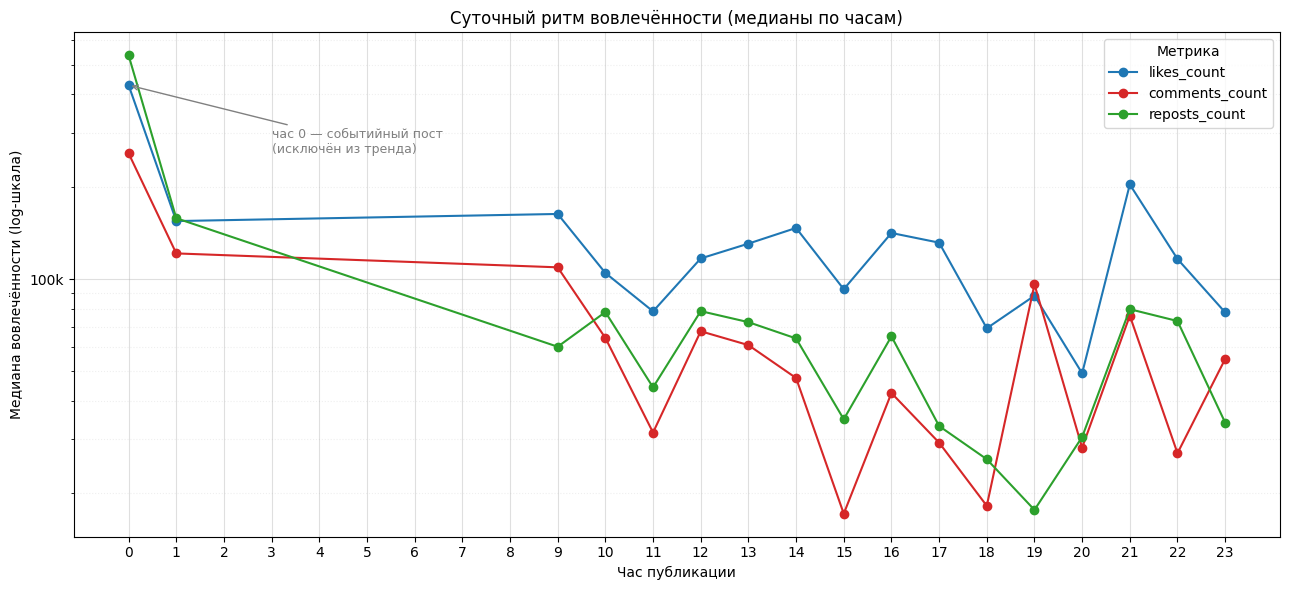

In [ ]:
from matplotlib.ticker import FuncFormatter
hourly = df.groupby('hour')[['likes_count','comments_count','reposts_count']].median()

n_by_hour = df.groupby('hour').size()

fig, ax = plt.subplots(figsize=(13, 6))

for col, color in zip(hourly.columns, ['#1f77b4', '#d62728', '#2ca02c']):
    ax.plot(hourly.index, hourly[col], marker='o', label=col, color=color)

ax.set_yscale('log')

ax.yaxis.set_major_formatter(FuncFormatter(
    lambda x, _: f'{x/1000:.0f}k' if x >= 1000 else f'{x:.0f}'
))

ax.grid(True, which='major', ls='-', alpha=0.4)
ax.grid(True, which='minor', ls=':', alpha=0.2)

ax.set_xlabel('Час публикации')
ax.set_ylabel('Медиана вовлечённости (log-шкала)')
ax.set_title('Суточный ритм вовлечённости (медианы по часам)')
ax.set_xticks(range(0, 24))
ax.legend(title='Метрика')

ax.annotate('час 0 — событийный пост\n(исключён из тренда)',
            xy=(0, hourly.loc[0, 'likes_count']),
            xytext=(3, hourly.loc[0, 'likes_count'] * 0.6),
            arrowprops=dict(arrowstyle='->', color='gray'),
            fontsize=9, color='gray')

plt.tight_layout()
plt.show()

По графику видно, что 21:00 — пик по лайкам и репостам, 9:00 — по комментариям.

Сравним метрики (медианы по количеству лайков, комментов, репостов) по дням недели и выведем на график.

In [ ]:
df.groupby("day_of_week", observed=False)[["likes_count", "comments_count", "reposts_count"]].median()

,likes_count,comments_count,reposts_count
day_of_week,,,
Monday,102086.0,59847.0,63262.0
Tuesday,76467.0,36173.0,36915.0
Wednesday,128205.0,66472.5,90024.5
Thursday,117330.5,39934.5,66896.0
Friday,93552.5,43576.0,39995.0
Saturday,138431.5,63857.0,73086.5
Sunday,114421.5,30774.0,38553.5


<Axes: xlabel='day_of_week'>

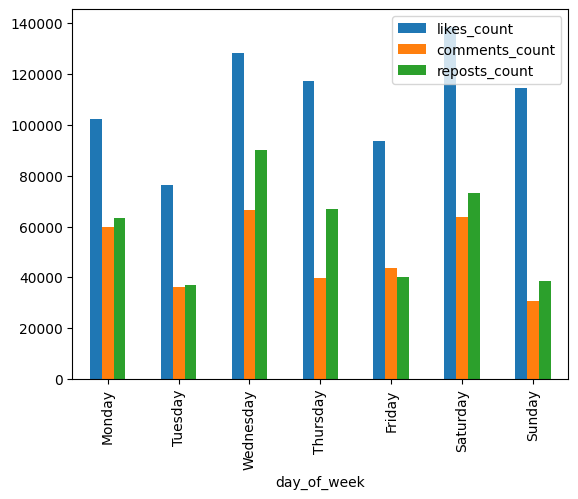

In [ ]:
df.groupby('day_of_week', observed=False)[['likes_count','comments_count','reposts_count']].median().plot(kind='bar')

Видно, что суббота и среда — лидеры по реакциям, вторник — аутсайдер.

Нарисуем также heatmap: час × день недели с указанием количества постов в скобках.

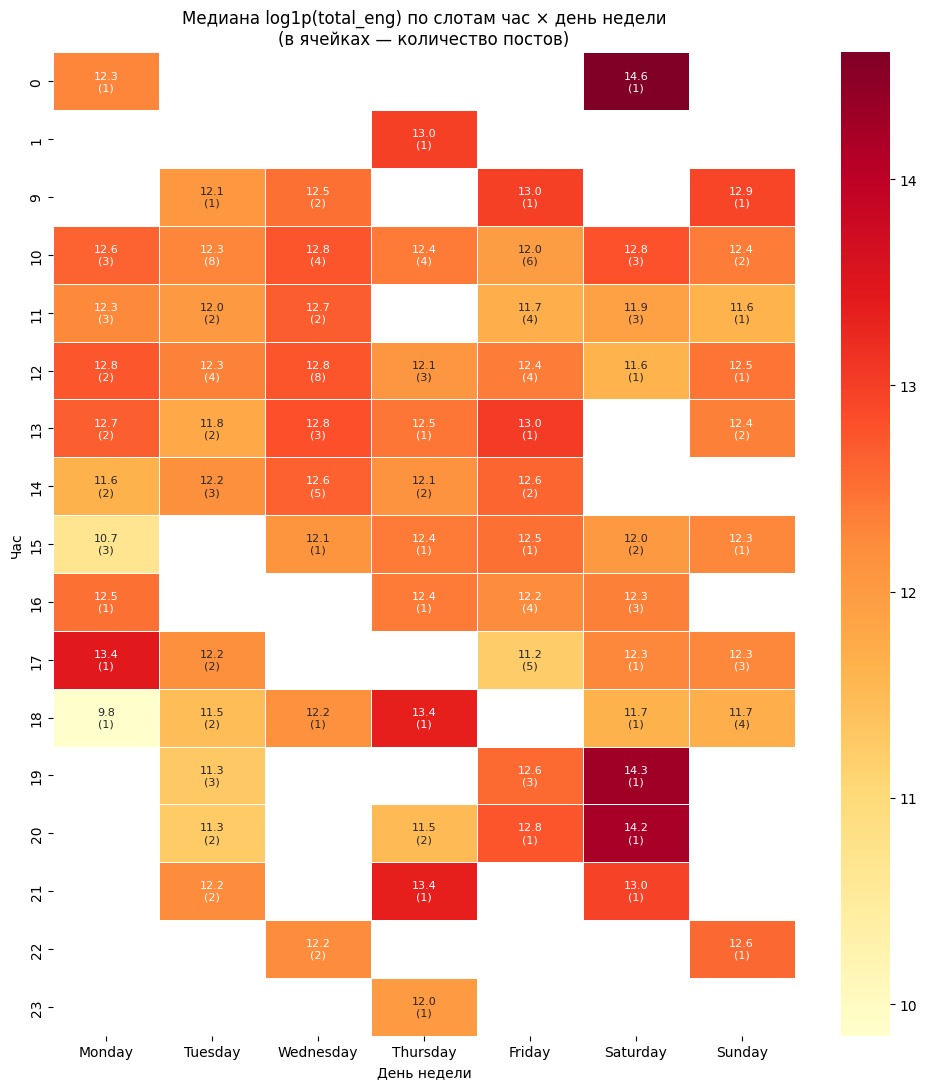

In [ ]:

# 1. Две матрицы медиана и кол-во постов
pivot_med = df.pivot_table(index='hour', columns='day_of_week',
                           values='log_total', aggfunc='median', observed=False)
pivot_n = df.pivot_table(index='hour', columns='day_of_week',
                         values='log_total', aggfunc='size', observed=False)

# 2. Текстовые подписи
annot = np.where(
    pivot_n.isna(),
    '',
    pivot_med.round(1).astype(str) + '\n(' + pivot_n.fillna(0).astype(int).astype(str) + ')'
)

# 3. График
fig, ax = plt.subplots(figsize=(10, 11))
sns.heatmap(
    pivot_med,
    annot=annot,
    fmt='',
    cmap='YlOrRd',
    annot_kws={'size': 8},
    linewidths=0.5,
    linecolor='white',
    ax=ax
)

ax.set_title('Медиана log1p(total) по слотам час × день недели\n(в ячейках — количество постов)')
ax.set_xlabel('День недели')
ax.set_ylabel('Час')
plt.tight_layout()
plt.show()

Так как большинство ячеек содержит по 1–2 поста, медианы в них не являются устойчивыми оценками. Устойчивые выводы возможны только для слота 10:00, где n ≥ 3 в большинстве дней и медиана держится в диапазоне 12.0–12.8.
Поэтому основной анализ эффекта времени проведён на агрегатах: медианы по часам и по дням недели.

###Влияние промежутка между постами на вовлечённость

Считаем корреляцию по Пирсону промежутков между постами и суммой всех реакций.

In [ ]:
df['interval_hours'] = df['created_at'].diff().dt.total_seconds() / 3600
df['total_eng'] = df['likes_count'] + df['comments_count'] + df['reposts_count']
df['interval_hours'].corr(df['total_eng'])

np.float64(0.15037773016860265)

Значение 0.15 при n=162 требует дополнительной проверки. Считаем корреляцию по Спирмену

In [ ]:
from scipy.stats import spearmanr
spearmanr(np.log1p(df['hours_since_prev']), np.log1p(df['log_total']))

SignificanceResult(statistic=np.float64(0.43868378211892617), pvalue=np.float64(5.251422102378035e-09))

Разрыв значений по Пирсону и Спирмену в 3 раза означает, что связь есть, но она нелинейная, и её «съедали» выбросы и хвосты. Рисуем график для наглядности.

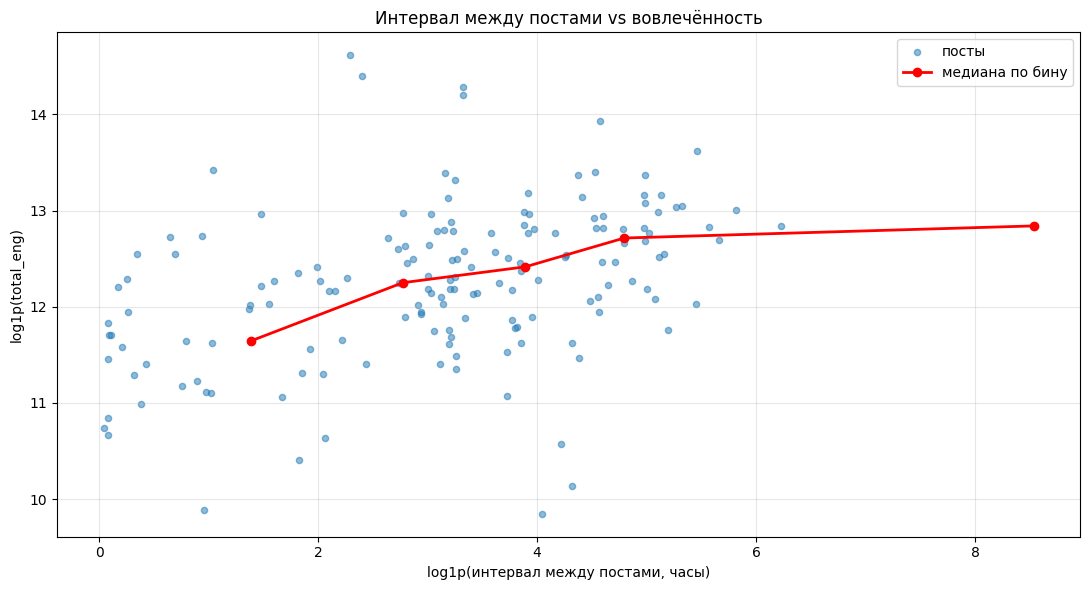

In [ ]:
df['log_eng'] = np.log1p(df['total_eng'])
df['log_interval'] = np.log1p(df['interval_hours'])

bins = [0, 6, 24, 72, 168, 10000]
df['interval_bin'] = pd.cut(df['interval_hours'], bins=bins)

med = df.groupby('interval_bin', observed=True)['log_eng'].median()

fig, ax = plt.subplots(figsize=(11, 6))

# Scatter: X — интервал (log), Y — вовлечённость (log)
ax.scatter(df['log_interval'], df['log_eng'], alpha=0.5, s=20, label='посты')

# Красная линия — медиана по бинам
# Середина каждого бина в лог-масштабе для красивого соединения
bin_centers = [np.log1p((bins[i] + bins[i+1]) / 2) for i in range(len(bins) - 1)]
ax.plot(bin_centers, med.values, color='red', marker='o', lw=2, label='медиана по бину')

ax.set_xlabel('log1p(интервал между постами, часы)')
ax.set_ylabel('log1p(total_eng)')
ax.set_title('Интервал между постами vs вовлечённость')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Интервал между постами влияет на вовлечённость, но с насыщением. Максимальный эффект достигается при паузе от 1 до 3 дней: медиана вовлечённости вырастает почти в 2 раза по сравнению с интервалом менее 6 часов. Дальнейшее увеличение паузы (более недели) не даёт прироста — кривая выходит на плато. Это значит, что оптимальная частота постинга — примерно один пост в 1–3 дня, а не ежедневно и не раз в месяц

### Влияние фото на количество реакций

Создаем признак наличия у поста прикрепленной фотографии. Посчитаем метрики реакций в двух группах, разделенных по этому признаку и выведем на график.

In [ ]:
def has_photo(url):
    if pd.isna(url):
        return False
    s = str(url).strip().lower()
    if s in ('', 'null', 'none', 'nan', 'http://', 'https://'):
        return False
    return s.startswith('http')

df['has_photo'] = df['original_pic_url'].apply(has_photo)

In [ ]:
df.groupby('has_photo')[['likes_count','comments_count','reposts_count','total_eng']].median()
df.groupby('has_photo')[['likes_count','comments_count','reposts_count','total_eng']].agg(['median','count'])

likes_count       comments_count       reposts_count        \
               median count         median count        median count   
has_photo                                                              
False         65660.5    60        26011.0    60       30395.0    60   
True         133962.5   102        61033.5   102       72636.5   102   

          total_eng        
             median count  
has_photo                  
False      131417.5    60  
True       286608.5   102

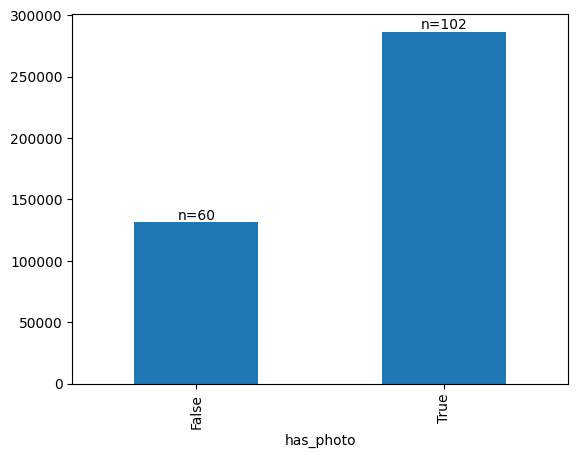

In [ ]:
med = df.groupby('has_photo')['total_eng'].median()
n = df.groupby('has_photo').size()
ax = med.plot(kind='bar')
for i, (m, nn) in enumerate(zip(med, n)):
    ax.text(i, m, f'n={nn}', ha='center', va='bottom')

Используем U-критерий Манна — Уитни для сравнения общего количества реакций на посты с фото и без.

In [ ]:
from scipy.stats import mannwhitneyu
u, p = mannwhitneyu(df.loc[df.has_photo, 'total_eng'],
                    df.loc[~df.has_photo, 'total_eng'],
                    alternative='two-sided')
print(f'U = {u:.0f}, p = {p:.4f}')

U = 4789, p = 0.0000


Наличие изображения — один из сильнейших факторов вовлечённости. Посты с фото имеют медианную вовлечённость в 2,2 раза выше, чем без него (131k vs 287k, Mann–Whitney U, p < 0,001). Эффект стабилен по всем трём метрикам и сильнее выражен для комментариев (×2,35) и репостов (×2,39), чем для лайков (×2,04). Это означает, что изображения не только увеличивают пассивный отклик, но и стимулируют обсуждение и распространение.

### Выводы

Рассмотренные факторы популярности поста по силе влияния:
* Наличие фото
* Время публикации (пик около 21:00)
* Ритм постинга (1–3 дня лучше, чем ежедневно)
